<a href="https://colab.research.google.com/github/1604056nizam/Rag-Models/blob/main/HippoRag.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Overview of HippoRAG

**HippoRAG** (Hippocampal Retrieval-Augmented Generation) is an advanced retrieval framework inspired by the complementary learning systems of the human brain. It is designed to address the limitations of standard semantic search in RAG systems, particularly when dealing with complex, multi-hop reasoning queries.

### Key Components:
* **Neocortex (Knowledge Graph)**: Stores the semantic memory. HippoRAG extracts entities and relations from the corpus using LLMs to build a comprehensive Knowledge Graph.
* **Hippocampus (Associative Index)**: Connects new experiences to existing memory. It utilizes **Personalized PageRank (PPR)** over the knowledge graph to dynamically retrieve relevant, interconnected nodes based on query entities.
* **LLM (Generator)**: Uses the retrieved context to synthesize the final answer.

### Advantages over Standard RAG:
* **Superior Multi-Hop Retrieval**: Easily links distant but logically connected pieces of information.
* **Biological Plausibility**: Leverages graph algorithms that mimic associative memory recall in human brains.
* **No Heavy Training**: Operates effectively on top of pre-trained LLMs and open-source graph frameworks.

## Step-by-Step Implementation of HippoRAG (Simplified)

We will implement a simplified version of HippoRAG containing:
1. **Passages & Entity Mapping** (mimicking the LLM extraction step).
2. **Knowledge Graph Construction** (representing the Neocortex).
3. **Personalized PageRank (PPR)** (representing the Hippocampus) to find structurally relevant entities given a query.
4. **Passage Retrieval & Ranking**.

In [1]:
import networkx as nx
import numpy as np
import pandas as pd

# 1. Define our toy document database (Passages)
passages = {
    "doc1": "Stanford University is located in California. It was founded by Leland Stanford.",
    "doc2": "Leland Stanford was a tycoon and politician who served as Governor of California.",
    "doc3": "The Governor of California resides in Sacramento and works at the State Capitol.",
    "doc4": "Sacramento is the capital city of California and has a rich history from the Gold Rush."
}

# 2. Mock entity extraction (normally done via LLM/NER models)
# Maps each passage to its detected entities
passage_entities = {
    "doc1": ["Stanford University", "California", "Leland Stanford"],
    "doc2": ["Leland Stanford", "Governor of California", "California"],
    "doc3": ["Governor of California", "Sacramento", "State Capitol"],
    "doc4": ["Sacramento", "California"]
}

# Display the dataset
pd.DataFrame([{"Document ID": k, "Passage Content": passages[k], "Extracted Entities": passage_entities[k]} for k in passages])

,Document ID,Passage Content,Extracted Entities
0,doc1,Stanford University is located in California. ...,"[Stanford University, California, Leland Stanf..."
1,doc2,Leland Stanford was a tycoon and politician wh...,"[Leland Stanford, Governor of California, Cali..."
2,doc3,The Governor of California resides in Sacramen...,"[Governor of California, Sacramento, State Cap..."
3,doc4,Sacramento is the capital city of California a...,"[Sacramento, California]"


### Neocortex: Constructing the Associative Knowledge Graph

In [2]:
# Initialize a graph using NetworkX
G = nx.Graph()

# Connect entities that co-occur in the same passage
for doc_id, entities in passage_entities.items():
    # Add edges between all pairs of entities in the same document
    for i in range(len(entities)):
        for j in range(i + 1, len(entities)):
            # If edge exists, increase weight; else create it
            if G.has_edge(entities[i], entities[j]):
                G[entities[i]][entities[j]]['weight'] += 1.0
            else:
                G.add_edge(entities[i], entities[j], weight=1.0, doc=doc_id)

print(f"Nodes (Entities): {G.nodes()}")
print(f"Edges: {G.edges(data=True)}")

Nodes (Entities): ['Stanford University', 'California', 'Leland Stanford', 'Governor of California', 'Sacramento', 'State Capitol']
Edges: [('Stanford University', 'California', {'weight': 1.0, 'doc': 'doc1'}), ('Stanford University', 'Leland Stanford', {'weight': 1.0, 'doc': 'doc1'}), ('California', 'Leland Stanford', {'weight': 2.0, 'doc': 'doc1'}), ('California', 'Governor of California', {'weight': 1.0, 'doc': 'doc2'}), ('California', 'Sacramento', {'weight': 1.0, 'doc': 'doc4'}), ('Leland Stanford', 'Governor of California', {'weight': 1.0, 'doc': 'doc2'}), ('Governor of California', 'Sacramento', {'weight': 1.0, 'doc': 'doc3'}), ('Governor of California', 'State Capitol', {'weight': 1.0, 'doc': 'doc3'}), ('Sacramento', 'State Capitol', {'weight': 1.0, 'doc': 'doc3'})]


### Hippocampus: query node activation and Personalized PageRank (PPR)
Given a query, we find query entities, map them to graph nodes, trigger initialization weights (personalization), and run PPR.

In [4]:
def hipporag_retrieve(query_entities, graph, passages, passage_entities, alpha=0.85):
    # Create a personalization vector for PageRank
    personalization = {node: 0.0 for node in graph.nodes()}

    # Only activate the nodes present in the query
    active_query_nodes = [node for node in query_entities if node in graph.nodes()]
    if not active_query_nodes:
        print("No query entities found in the graph.")
        return []

    # Distribute initial activation evenly among query entities
    for node in active_query_nodes:
        personalization[node] = 1.0 / len(active_query_nodes)

    # Run Personalized PageRank (PPR)
    # This simulates spreading activation through the hippocampus
    pagerank_scores = nx.pagerank(graph, alpha=alpha, personalization=personalization, weight='weight')

    # Score passages based on the PageRank of their constituent entities
    passage_scores = {}
    for doc_id, entities in passage_entities.items():
        # Passage score can be the sum of its entities' pagerank scores
        score = sum(pagerank_scores.get(ent, 0.0) for ent in entities)
        passage_scores[doc_id] = score

    # Sort passages based on scores
    sorted_passages = sorted(passage_scores.items(), key=lambda x: x[1], reverse=True)

    # Format results
    results = []
    for doc_id, score in sorted_passages:
        results.append({
            "doc_id": doc_id,
            "score": score,
            "text": passages[doc_id],
            "entities": passage_entities[doc_id]
        })
    return results, pagerank_scores

### Testing Multi-Hop Retrieval with a Complex Query
Let's ask a question that requires connecting information: *"Who founded the university in the state where the State Capitol is located?"*
To solve this, a retriever must associate: `State Capitol` -> `Sacramento` / `Governor of California` -> `California` -> `Leland Stanford` -> `Stanford University`.

In [5]:
# Query entities detected:
query_entities = ["State Capitol", "Stanford University"]

results, pagerank_scores = hipporag_retrieve(query_entities, G, passages, passage_entities)

print("--- ENTITY ACTIVATION SCORES (PPR) ---")
for entity, score in sorted(pagerank_scores.items(), key=lambda x: x[1], reverse=True):
    print(f"{entity:25s} : {score:.4f}")

print("\n--- RANKED PASSAGES FOR GENERATION ---")
for r in results:
    print(f"[{r['doc_id']}] (Score: {r['score']:.4f}): {r['text']}")

--- ENTITY ACTIVATION SCORES (PPR) ---
California                : 0.2130
Governor of California    : 0.1765
Leland Stanford           : 0.1728
State Capitol             : 0.1517
Stanford University       : 0.1479
Sacramento                : 0.1382

--- RANKED PASSAGES FOR GENERATION ---
[doc2] (Score: 0.5623): Leland Stanford was a tycoon and politician who served as Governor of California.
[doc1] (Score: 0.5337): Stanford University is located in California. It was founded by Leland Stanford.
[doc3] (Score: 0.4663): The Governor of California resides in Sacramento and works at the State Capitol.
[doc4] (Score: 0.3511): Sacramento is the capital city of California and has a rich history from the Gold Rush.


### Visualizing the Neocortex (Knowledge Graph) and Activation Spreading
We will visualize the network using `matplotlib`. The size of each node will be proportional to its Personalized PageRank score (activation), showing how information flows from the query nodes to the rest of the graph.

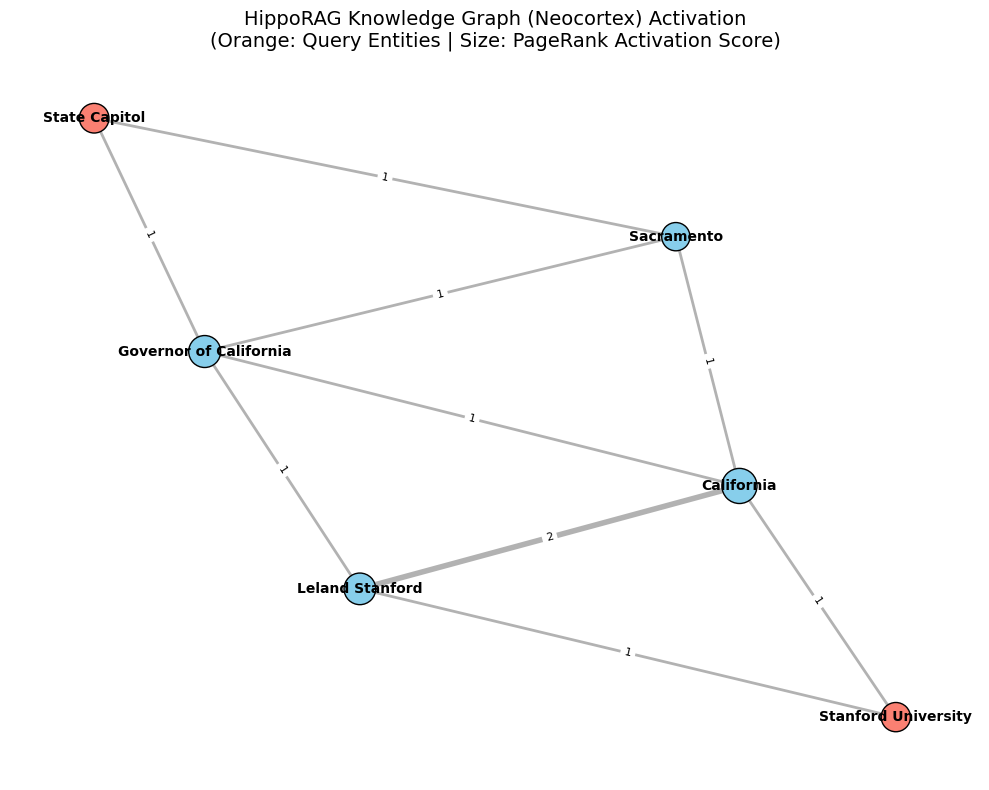

In [6]:
import matplotlib.pyplot as plt

# Set figure size
plt.figure(figsize=(10, 8))

# Define layout for nodes
pos = nx.spring_layout(G, seed=42)

# Map nodes to colors based on whether they were part of the initial query
node_colors = []
for node in G.nodes():
    if node in query_entities:
        node_colors.append('salmon')  # Query entry points
    else:
        node_colors.append('skyblue') # Discovered associative nodes

# Map node sizes based on their PageRank activation scores
# We scale the values so they are clearly visible on the plot
node_sizes = [3000 * pagerank_scores.get(node, 0.1) for node in G.nodes()]

# Draw nodes
nx.draw_networkx_nodes(G, pos, node_size=node_sizes, node_color=node_colors, edgecolors='black')

# Draw edges with widths proportional to weight
edges = G.edges(data=True)
weights = [d['weight'] * 2 for u, v, d in edges]
nx.draw_networkx_edges(G, pos, width=weights, edge_color='gray', alpha=0.6)

# Draw labels
nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

# Draw edge weight labels
edge_labels = {(u, v): int(d['weight']) for u, v, d in edges}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8)

plt.title("HippoRAG Knowledge Graph (Neocortex) Activation\n(Orange: Query Entities | Size: PageRank Activation Score)", fontsize=14)
plt.axis('off')
plt.tight_layout()
plt.show()